# Task 1

We have read this paper:

Waldner, F., Balke, G., Rech, F. et al. Data-driven insights into (E-)bike-sharing: mining a large-scale dataset on usage and urban characteristics: descriptive analysis and performance modeling. Transportation 52, 2433–2473 (2025). https://doi.org/10.1007/s11116-025-10661-2

This task largely references to the "Preprocessing and descriptive analysis" section of the paper.


## 1. Preprocessing

In this section, we select valid bikes and cities, that are, bikes with trip records in trips_small.csv and known propulsion types in bike_types.csv, and cities with trip records in trips_small.csv and "owning" at least 10 bikes according to our definition.

We define the data hierarchy as **city level** and **bike level**. We call each city a bike sharing system (BSS). In each BSS numerous bikes and stations are operated.

We include one external dataset from https://github.com/TUMFTM/european-bike-sharing-dataset to get the operating areas of the cities concerned.

In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# static table
cities = pd.read_csv("../data/cities.csv")
stations = pd.read_csv(("../data/stations.csv"))
bikes = pd.read_csv(("../data/bikes.csv"))
bike_types = pd.read_csv(("../data/bike_types.csv"))

# dynamic table
trips = pd.read_csv(("../data/trips_small.csv"))

# Use external data from https://github.com/TUMFTM/european-bike-sharing-dataset/blob/main/sample/city_areas.csv
areas = pd.read_csv("../data/city_areas.csv")


### Selection of valid bikes

We approach the data from **bike level** first.

We have discovered that bikes.csv has 88436 bikes, but trips_small.csv has trip records of only 26424 bikes. From our analysis we exclude bikes that has no trip records.

We also exclude bikes with unknown propulsion type (null propulsion_type in bike_types.csv) from our analysis.


In [161]:
print(f"Number of cities in cities.csv: {cities['id'].nunique()}")
print(f"Number of cities appearing in trips_small.csv: {trips['city_id'].nunique()}")

# link bikes to their propulsion types
bike_propulsion_type = (
    bikes[["id", "bike_type_id"]]
    .rename(columns={"id": "bike_id"})
    .merge(
        bike_types[["id", "propulsion_type"]],
        left_on="bike_type_id",
        right_on="id",
        how="left",
    )
    .drop(columns="id")
)

# select bikes with known propulsion types
known_propulsion_bikes = bike_propulsion_type.dropna(subset=["propulsion_type"])
bikes_valid = known_propulsion_bikes[
    known_propulsion_bikes["bike_id"].isin(trips["bike_id"])
].copy()

print(f"Bikes with known propulsion type: {known_propulsion_bikes['bike_id'].nunique()}")
print(f"Valid bikes with trip records and known propulsion type: {bikes_valid['bike_id'].nunique()}")


Number of cities in cities.csv: 267
Number of cities appearing in trips_small.csv: 185
Bikes with known propulsion type: 87386
Valid bikes with trip records and known propulsion type: 25833


### Bike's belonging problem

Now we start to bridge **bike level** data with **city level** data. Remember in our terminology a city is referred to as a bike sharing system (BSS).

The scale of a BSS is directly linked to the number of bikes the system has. Since a bike can have trips records in multiple cities, we assign a **primary city** for each bike, i.e. the city that "owns" this bike. A bike's primary city is defined as the city where it has the longest **total trip duration**.



In [162]:
bike_city_durations = (
    trips.loc[trips["bike_id"].isin(bikes_valid["bike_id"])]
    .groupby(["city_id", "bike_id"], as_index=False)["duration"]
    .sum()
    .rename(columns={"duration": "total_duration"})
)
bike_primary_city = (
    bike_city_durations.sort_values("total_duration", ascending=False)
    .drop_duplicates(subset="bike_id")[["city_id", "bike_id"]]
)
cities_valid = bike_primary_city["city_id"].drop_duplicates()

print(f"Cities with trips from valid bikes: {bike_city_durations['city_id'].nunique()}")
print(f"Primary cities assigned: {bike_primary_city['city_id'].nunique()}")
print(f"Valid cities retained: {cities_valid.shape[0]}")


Cities with trips from valid bikes: 185
Primary cities assigned: 184
Valid cities retained: 184


Note that among the 185 cities, one city is not a "primary" city because for all bikes that have trips in it, they have longer trip durations in another city. We exclude this city from our analysis since it is not a representitive city.

### Selection of valid cities

**city_bikes** city_id | n_bikes

Now that every city has been granted with their bike ownership, we can approach the data at the **city level**. 

In order for a city to qualify as a bike sharing system (BSS), it needs to reach a certain scale. Here we define the minimum qualifying scale as 10 bikes. Thus cities with fewer than 10 bikes will be excluded from our subsequent analysis.

In this section we count the number of bikes in each city. 


In [163]:
# combine bikes, their propulsion types, and their primary city
city_bike_propulsion = bike_propulsion_type.merge(
    bike_primary_city, on="bike_id", how="inner"
)

# n_bikes in each city
city_bikes = (
    city_bike_propulsion.groupby("city_id")["bike_id"]
    .count()
    .reset_index(name="n_bikes")
)

# select sizable cities only
city_size = city_bikes.loc[city_bikes["n_bikes"] >= 10].copy()
excluded_cities = len(city_bikes) - len(city_size)
city_bike_propulsion = city_bike_propulsion[
    city_bike_propulsion["city_id"].isin(city_size["city_id"])
]
print(f"Cities excluded for having fewer than 10 bikes: {excluded_cities}")
print(f"Cities retained after size filtering: {len(city_size)}")


Cities excluded for having fewer than 10 bikes: 6
Cities retained after size filtering: 178


### Valid data accquired.

**Now we have got both valid bikes and valid cities, we will conduct the subsequent work only using these valid data.**

REMINDER: LAST EDIT ENDED HERE

### By organisational form: 143 station based, 35 free floating (including hybrid).

In [164]:
city_organization_form = (
    cities.merge(city_size[["city_id"]], left_on="id", right_on="city_id", how="inner")
    [["id", "return_to_official_only"]]
    .rename(columns={"id": "city_id"})
)
print("Cities by organizational form:")
print(city_organization_form["return_to_official_only"].value_counts())


Cities by organizational form:
return_to_official_only
True     143
False     35
Name: count, dtype: int64


### By propulsion type: 131 conventional, 36 mixed, 11 electric.

We also categorize BSSs by propulsion type: a city with 100% of human powered bikes is a conventional BSS, one with 0% human powered bikes is (fully) electric, while one in between is mixed.


In [165]:
# Categorize each city by its share of human-powered bikes.
city_human_share = (
    city_bike_propulsion.assign(
        is_human=city_bike_propulsion["propulsion_type"] == "human"
    )
    .groupby("city_id")["is_human"]
    .mean()
    .reset_index(name="proportion_of_human_powered_bikes")
)


def categorize_propulsion_type(proportion):
    if proportion == 1:
        return "conventional"
    if proportion == 0:
        return "electric"
    return "mixed"


city_human_share["type"] = city_human_share[
    "proportion_of_human_powered_bikes"
].apply(categorize_propulsion_type)
city_propulsion_type = city_human_share
print("Cities by propulsion type:")
print(city_propulsion_type["type"].value_counts())


Cities by propulsion type:
type
conventional    131
mixed            36
electric         11
Name: count, dtype: int64


We see that most of bikes are human powered:

In [166]:
propulsion_counts = bike_propulsion_type["propulsion_type"].value_counts()
print("Bikes by propulsion type:")
print(propulsion_counts)


Bikes by propulsion type:
propulsion_type
human              81530
electric_assist     5856
Name: count, dtype: int64


### n_stations in each city

**city_stations:** city_id | n_stations

In [167]:
city_stations = (
    stations[stations["city_id"].isin(city_size["city_id"])]
    .groupby("city_id")["id"]
    .count()
    .reset_index(name="n_stations")
)

print("Station counts per city (first five rows):")
print(city_stations.head())


Station counts per city (first five rows):
   city_id  n_stations
0        7          37
1       23          29
2       64          44
3       88          41
4      128          44


### n_racks in each city

We noticed that some special racks has negative values. Using AI to search info: there are two reporting schemes from Nextbike. If special_racak is positive, bike_racks means regular racks; if negative, bike_racks means number of total racks, the "-" sign means reserved for charging e-bikes. 

In [168]:
stations["total_racks"] = np.where(
    stations["special_racks"] < 0,
    stations["bike_racks"],                                      # subtractive: bike_racks is already gross total
    stations["bike_racks"] + stations["special_racks"].fillna(0) # additive: add both
)

# city_bikes we already have, now calculate city_racks
city_racks = (
    stations.groupby("city_id")["total_racks"]
    .sum()
    .reset_index(name="n_racks")
)


### city area

use city_areas.csv from github, meaning cf paper Table 13

**city_area**: city_id 

In [169]:
# Calculate operational area in square kilometers.
import geopandas as gpd
from shapely import wkt

areas["geometry"] = areas["geom_ewkt"].apply(lambda value: wkt.loads(value.split(";")[-1]))
gdf = gpd.GeoDataFrame(areas, geometry="geometry", crs="EPSG:4326")
gdf_projected = gdf.to_crs(epsg=6933)
gdf["area_sq_km"] = gdf_projected.geometry.area / 1_000_000
city_areas = gdf[["city_id", "area_sq_km"]]


### All in one city level dataframe and valid trip records.

After preprocessing, we get two dataframes: **city_all** includes all city-level features that we are intersted in, and **trips_valid** includes trips having known start time and made by bikes whose propulsion types are known. We will use these two dataframes in the next session.

**city_all**: city_id | size | n_stations| n_bikes| n_racks | area | organization type | propulsion type

In [170]:
city_all = (
    city_size
    .merge(city_stations, on="city_id")
    .merge(city_organization_form, on="city_id")
    .merge(city_propulsion_type, on="city_id")
    .merge(city_racks, on="city_id")
    .merge(city_areas, on="city_id")
    .drop(columns="proportion_of_human_powered_bikes")
)

trip_valid = (
    bike_propulsion_type.merge(trips, on="bike_id")
    .dropna(subset=["time_start"])
)
trips_valid = trip_valid

print(f"Final city-level dataframe: {city_all.shape[0]} cities, {city_all.shape[1]} columns.")
print(f"Final valid-trip dataframe: {trip_valid.shape[0]} trips, {trip_valid.shape[1]} columns.")


Final city-level dataframe: 178 cities, 7 columns.
Final valid-trip dataframe: 1161376 trips, 15 columns.


### Result
After preprocessing,

- we have identified 178 valid cities with 25803 valid bikes. These are cities that have bike trip records and have a fleet size of more than 10 bikes, and bikes that have trip records and identified propulsion type. 

- A majority (87.6% / 22621) of bikes are classic, human-powered bikes, the other (12.4% / 3212) are electric assisted bikes. 

- 87.1% or 22475 bikes belong to station based BSS, the other belong to free floating (including hybrid) BSS. 

- In total, there are 1159030 valid trips with a line-of-flight distance of 2075852 km.

In [171]:
# Summary of the final preprocessed datasets.
n_valid_cities = city_all["city_id"].nunique()
n_valid_bikes = city_all["n_bikes"].sum()
n_human_bikes = city_bike_propulsion["propulsion_type"].eq("human").sum()
n_typed_bikes = len(city_bike_propulsion)
n_station_based_bikes = city_all.loc[
    city_all["return_to_official_only"], "n_bikes"
].sum()
n_free_floating_bikes = n_valid_bikes - n_station_based_bikes
distance_km = trip_valid["distance"].sum() / 1000

print(f"Valid cities: {n_valid_cities}")
print(f"Valid bikes: {n_valid_bikes}")
print(
    f"Human-powered bikes: {n_human_bikes} "
    f"({n_human_bikes / n_typed_bikes:.1%}); "
    f"electric-assist bikes: {n_typed_bikes - n_human_bikes} "
    f"({(n_typed_bikes - n_human_bikes) / n_typed_bikes:.1%})."
)
print(
    f"Station-based bikes: {n_station_based_bikes}; "
    f"free-floating or hybrid bikes: {n_free_floating_bikes}."
)
print(f"Valid trips: {len(trip_valid)}")
print(f"Total trip distance: {distance_km:.1f} km")

Valid cities: 178
Valid bikes: 25803
Human-powered bikes: 22597 (87.6%); electric-assist bikes: 3206 (12.4%).
Station-based bikes: 22475; free-floating or hybrid bikes: 3328.
Valid trips: 1161376
Total trip distance: 2080923.1 km


## 2. Descriptive Analysis

### Categorizing BSS by size
Small systems: 10 <= n_bikes <= 100
Medium: 101 <= n_bikes <= 500
Large: 501 <= n_bikes

In [172]:
def categorize_by_size(n_bikes):
    if n_bikes >= 501:
        return "large"
    if n_bikes >= 101:
        return "medium"
    return "small"


city_all["size"] = city_all["n_bikes"].apply(categorize_by_size)
print("Cities by system size:")
print(city_all["size"].value_counts())


Cities by system size:
size
small     97
medium    72
large      9
Name: count, dtype: int64


### Indicators

In [173]:
bss_small = city_all[city_all["size"] == "small"]
bss_medium = city_all[city_all["size"] == "medium"]
bss_large = city_all[city_all["size"] == "large"]

In [174]:
# AI generated code
def get_indicator(bss):
    n_systems = len(bss)
    # Average per-system ratios; zero denominators are excluded as undefined.
    bikes_per_station = bss["n_bikes"].div(bss["n_stations"].replace(0, np.nan))
    bikes_per_rack = bss["n_bikes"].div(bss["n_racks"].replace(0, np.nan))
    bikes_per_sq_km = bss["n_bikes"].div(bss["area_sq_km"].replace(0, np.nan))
    stations_per_sq_km = bss["n_stations"].div(bss["area_sq_km"].replace(0, np.nan))

    return {
        "n_systems": n_systems,
        "avg_bikes_per_station": bikes_per_station.mean(),
        "avg_bikes_per_rack": bikes_per_rack.mean(),
        "avg_bikes_per_sq_km": bikes_per_sq_km.mean(),
        "avg_stations_per_sq_km": stations_per_sq_km.mean(),
        "share_mixed_propulsion_bss_pct": bss["type"].eq("mixed").mean() * 100,
        "share_electric_bss_pct": bss["type"].eq("electric").mean() * 100,
    }

In [175]:
# AI generated code
size_indicators = pd.DataFrame.from_dict(
    {
        "small": get_indicator(bss_small),
        "medium": get_indicator(bss_medium),
        "large": get_indicator(bss_large),
    },
    orient="index",
).rename_axis("size")
size_indicators

,n_systems,avg_bikes_per_station,avg_bikes_per_rack,avg_bikes_per_sq_km,avg_stations_per_sq_km,share_mixed_propulsion_bss_pct,share_electric_bss_pct
size,,,,,,,
small,97,5.758213,1.567236,4.675725,0.844523,20.618557,4.123711
medium,72,14.021020,2.691682,10.624351,1.083457,19.444444,8.333333
large,9,60.087447,8.014312,39.070115,0.764905,22.222222,11.111111


### Visualizations

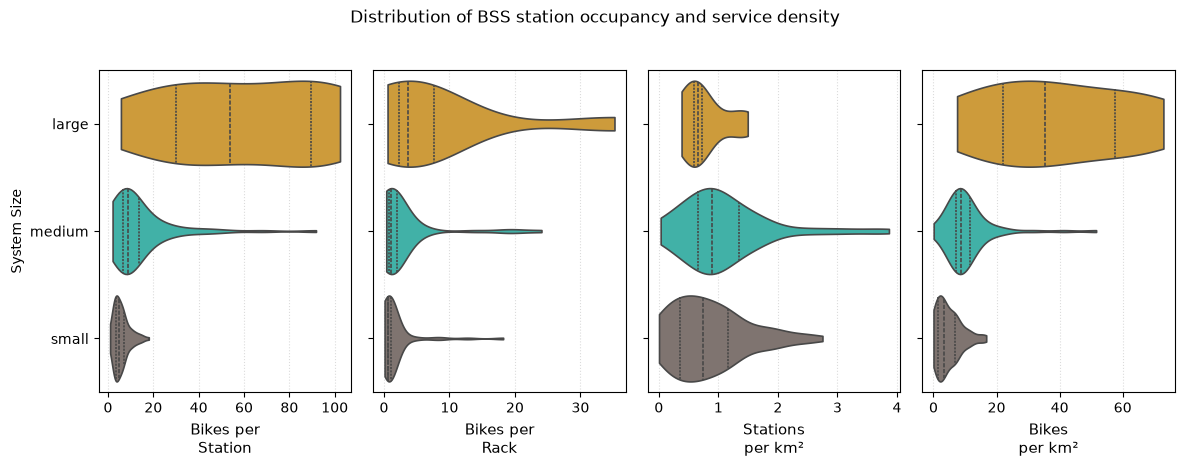

In [176]:
# Fig 4
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}

plot_data = city_all.assign(
    bikes_per_station=city_all["n_bikes"].div(city_all["n_stations"].replace(0, np.nan)),
    bikes_per_rack=city_all["n_bikes"].div(city_all["n_racks"].replace(0, np.nan)),
    stations_per_sq_km=city_all["n_stations"].div(city_all["area_sq_km"].replace(0, np.nan)),
    bikes_per_sq_km=city_all["n_bikes"].div(city_all["area_sq_km"].replace(0, np.nan)),
).melt(
    id_vars="size",
    value_vars=[
        "bikes_per_station",
        "bikes_per_rack",
        "stations_per_sq_km",
        "bikes_per_sq_km",
    ],
    var_name="indicator",
    value_name="value",
).dropna(subset=["value"])

indicators = [
    ("bikes_per_station", "Bikes per\nStation"),
    ("bikes_per_rack", "Bikes per\nRack"),
    ("stations_per_sq_km", "Stations\nper km²"),
    ("bikes_per_sq_km", "Bikes\nper km²"),
]
fig, axes = plt.subplots(1, len(indicators), figsize=(12, 4.5), sharey=True)

for ax, (indicator, label) in zip(axes, indicators):
    sns.violinplot(
        data=plot_data[plot_data["indicator"] == indicator],
        x="value",
        y="size",
        hue="size",
        order=size_order,
        hue_order=size_order,
        palette=size_palette,
        dodge=False,
        cut=0,
        inner="quart",
        linewidth=1.2,
        legend=False,
        ax=ax,
    )
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel("System Size" if ax is axes[0] else "")
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False)
    ax.grid(axis="x", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle("Distribution of BSS station occupancy and service density", y=1.03)
fig.tight_layout()
# fig.savefig("images/bss_indicators_by_system_size.png", dpi=300, bbox_inches="tight")
plt.show()

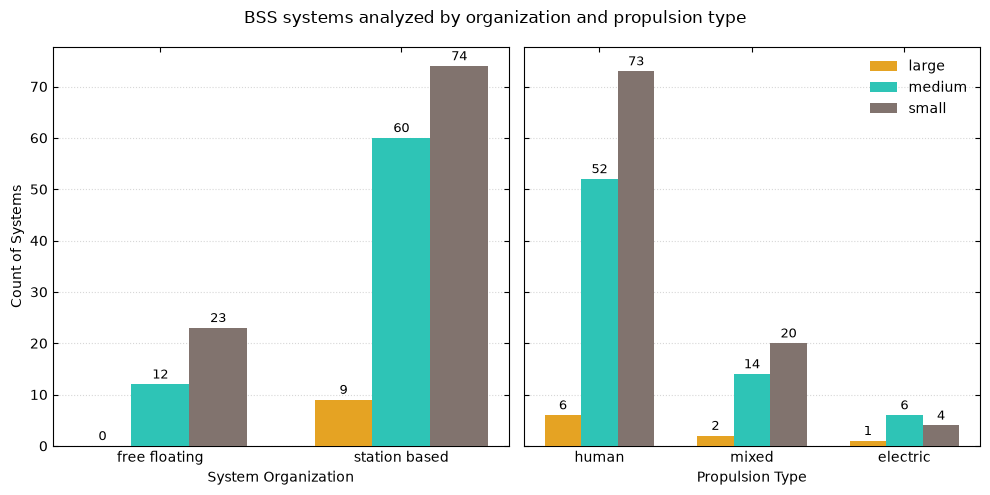

In [177]:
# Fig 5
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}
size_labels = {"large": "large", "medium": "medium", "small": "small"}

organization_counts = pd.crosstab(
    city_all["return_to_official_only"].map({False: "free floating", True: "station based"}),
    city_all["size"],
).reindex(index=["free floating", "station based"], columns=size_order, fill_value=0)
propulsion_counts = pd.crosstab(
    city_all["type"].replace({"conventional": "human"}),
    city_all["size"],
).reindex(index=["human", "mixed", "electric"], columns=size_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
bar_width = 0.24

for ax, counts, xlabel in zip(
    axes,
    [organization_counts, propulsion_counts],
    ["System Organization", "Propulsion Type"],
):
    positions = np.arange(len(counts.index))
    for i, size in enumerate(size_order):
        bars = ax.bar(
            positions + (i - 1) * bar_width,
            counts[size].to_numpy(),
            width=bar_width,
            label=size_labels[size],
            color=size_palette[size],
            zorder=3,
        )
        ax.bar_label(bars, padding=2, fontsize=9)

    ax.set_xticks(positions, counts.index)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)

axes[0].set_ylabel("Count of Systems")
axes[1].legend(title=None, frameon=False, loc="upper right")
fig.suptitle("BSS systems analyzed by organization and propulsion type")
fig.tight_layout()
# fig.savefig("images/bss_system_counts_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

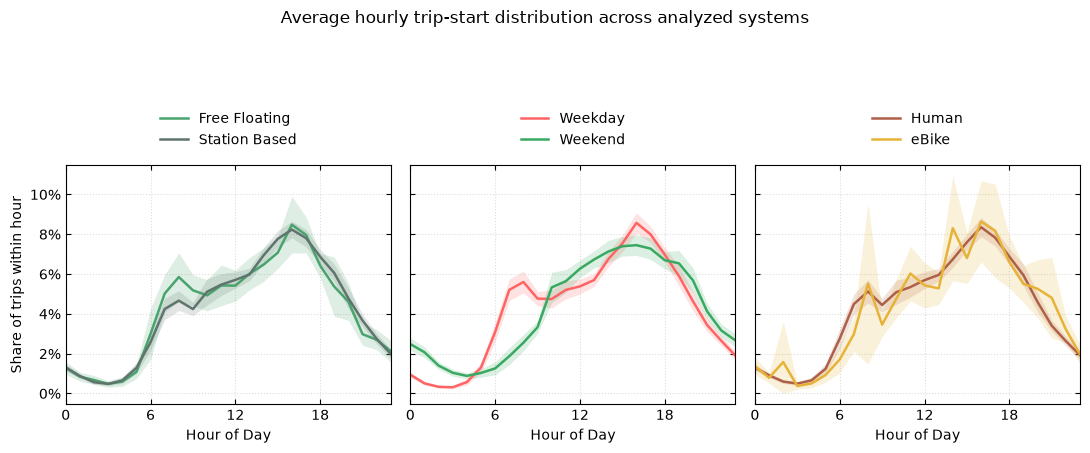

In [178]:
from matplotlib.ticker import PercentFormatter

# Restrict temporal profiles to the systems included in df and trips with known propulsion.
temporal_trips = (
    trips.merge(
        bike_propulsion_type[["bike_id", "propulsion_type"]],
        on="bike_id",
        how="inner",
    )
    .merge(city_all[["city_id", "return_to_official_only"]], on="city_id", how="inner")
    .merge(
        cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
        on="city_id",
        how="left",
    )
)
if temporal_trips["timezone"].isna().any():
    raise ValueError("A trip city is missing its timezone.")

temporal_trips["hour"] = 0
temporal_trips["day_type"] = ""
for timezone, row_indices in temporal_trips.groupby("timezone").groups.items():
    local_time = pd.to_datetime(
        temporal_trips.loc[row_indices, "time_start"], unit="s", utc=True
    ).dt.tz_convert(timezone)
    temporal_trips.loc[row_indices, "hour"] = local_time.dt.hour.to_numpy()
    temporal_trips.loc[row_indices, "day_type"] = np.where(
        local_time.dt.day_of_week.to_numpy() < 5, "Weekday", "Weekend"
    )

temporal_trips["organization"] = temporal_trips["return_to_official_only"].map(
    {False: "Free Floating", True: "Station Based"}
)
temporal_trips["propulsion"] = temporal_trips["propulsion_type"].map(
    {"human": "Human", "electric_assist": "eBike"}
)


def hourly_mean_ci(group):
    counts = (
        group.groupby(["city_id", "hour"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )
    system_shares = counts.div(counts.sum(axis=1), axis=0)
    mean = system_shares.mean(axis=0).to_numpy()
    margin = (1.96 * system_shares.sem(axis=0).fillna(0)).to_numpy()
    return mean, margin


panels = [
    (
        "organization",
        [("Free Floating", "#48a36c"), ("Station Based", "#60746e")],
    ),
    ("day_type", [("Weekday", "#ff6464"), ("Weekend", "#39a962")]),
    ("propulsion", [("Human", "#ad6047"), ("eBike", "#e6b338")]),
]
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
hours = np.arange(24)

for ax, (group_column, categories) in zip(axes, panels):
    for category, color in categories:
        mean, margin = hourly_mean_ci(
            temporal_trips[temporal_trips[group_column] == category]
        )
        ax.plot(hours, mean, color=color, linewidth=1.8, label=category)
        ax.fill_between(
            hours,
            np.maximum(mean - margin, 0),
            mean + margin,
            color=color,
            alpha=0.18,
            linewidth=0,
        )

    ax.set_xlim(0, 23)
    ax.set_xticks([0, 6, 12, 18])
    ax.set_xlabel("Hour of Day")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02))

axes[0].set_ylabel("Share of trips within hour")
fig.suptitle("Average hourly trip-start distribution across analyzed systems", y=1.12)
fig.tight_layout()
fig.savefig("images/bss_temporal_distribution.png", dpi=300, bbox_inches="tight")
plt.show()